# PhishGuard XAI - Pipeline Machine Learning

Notebook ini menjalankan SELURUH proses machine learning secara berurutan:
1. **Preprocessing** - gabungkan semua dataset di `dataset/raw/` menjadi satu data bersih.
2. **Training** - latih 4 algoritma (Random Forest, XGBoost, LightGBM, CatBoost) + scaler.
3. **Evaluasi** - hitung metrik tiap algoritma untuk halaman Perbandingan.
4. **SHAP** - buat explainer agar prediksi dapat dijelaskan.

Frontend (aplikasi web Flask) hanya *memuat* artefak hasil notebook ini.

> Jalankan sel dari atas ke bawah. Pastikan dependensi di `requirements.txt` sudah terpasang.


## 0. Persiapan


In [2]:
import sys, os
# Tambahkan root project ke path agar modul bisa diimpor dari notebooks/.
ROOT = os.path.abspath('..')
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)

import pandas as pd
print('Root project:', ROOT)

Root project: c:\xampp\htdocs\phishing-detector-xai


## 1. Preprocessing

Letakkan satu atau beberapa file CSV berlabel di `dataset/raw/` (nama bebas).
Untuk dataset berlabel angka dengan konvensi berbeda (mis. 1=legitimate),
buat `dataset/raw/datasets.json` (lihat README). Sel di bawah menggabungkan
semuanya, membuang duplikat, mengekstraksi 40 fitur, lalu menyimpan satu data bersih.


In [3]:
from training.preprocessing import load_all_raw, load_and_extract

# Intip gabungan mentah dulu (URL + label) sebelum ekstraksi fitur.
raw = load_all_raw()
print('Total baris unik:', len(raw))
display(raw.head())
print(raw['label'].value_counts().rename({0:'legitimate',1:'phishing'}))

[preprocessing] Menemukan 5 file dataset di C:\xampp\htdocs\phishing-detector-xai\dataset\raw
[preprocessing]  * Dataset.csv: label ANGKA tanpa konfigurasi -> asumsi 1=phishing. Jika keliru, tambahkan entri di dataset/raw/datasets.json.
[preprocessing]  - Dataset.csv: 116600 baris valid (url='url', label='label')
[preprocessing]  - Phishing URLs.csv: 54807 baris valid (url='url', label='Type')
[preprocessing]  * phishing_dataset.csv: label ANGKA tanpa konfigurasi -> asumsi 1=phishing. Jika keliru, tambahkan entri di dataset/raw/datasets.json.
[preprocessing]  - phishing_dataset.csv: 120000 baris valid (url='url', label='label')
[preprocessing]  - PhiUSIIL_Phishing_URL_Dataset.csv: 235795 baris valid (url='URL', label='label')
[preprocessing]  - URL dataset.csv: 450176 baris valid (url='url', label='type')
[preprocessing] Total 977378 baris -> 969647 setelah buang duplikat
Total baris unik: 969647


,url,label
0,https://www.rmit.edu.au/,0
1,http://www.latrobe.edu.au/,0
2,https://www.cqu.edu.au/,0
3,http://bond.edu.au/,0
4,http://www.csu.edu.au/,0


label
legitimate    638048
phishing      331599
Name: count, dtype: int64


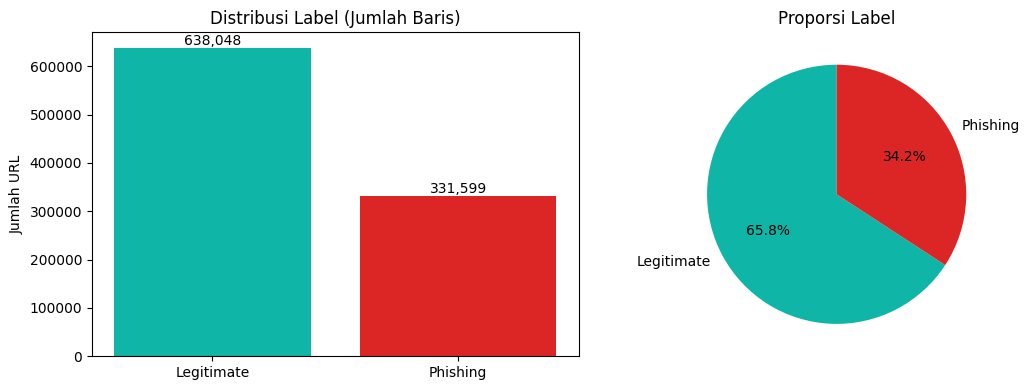

In [4]:
# Visualisasi distribusi label (EDA) -- gambaran keseimbangan kelas sebelum training.
import matplotlib.pyplot as plt

counts = raw['label'].value_counts().sort_index()
labels_id = ['Legitimate', 'Phishing']
colors = ['#0FB5A6', '#DC2626']

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(labels_id, counts.values, color=colors)
axes[0].set_title('Distribusi Label (Jumlah Baris)')
axes[0].set_ylabel('Jumlah URL')
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f'{v:,}', ha='center', va='bottom')

axes[1].pie(counts.values, labels=labels_id, colors=colors, autopct='%1.1f%%', startangle=90)
axes[1].set_title('Proporsi Label')

plt.tight_layout()
plt.show()

In [5]:
# Ekstraksi 40 fitur + simpan dataset/processed (mengembalikan X, y, nama fitur).
X, y, feature_names = load_and_extract()
print('Bentuk X:', X.shape, '| jumlah fitur:', len(feature_names))
display(X.head())

[preprocessing] Menemukan 5 file dataset di C:\xampp\htdocs\phishing-detector-xai\dataset\raw
[preprocessing]  * Dataset.csv: label ANGKA tanpa konfigurasi -> asumsi 1=phishing. Jika keliru, tambahkan entri di dataset/raw/datasets.json.
[preprocessing]  - Dataset.csv: 116600 baris valid (url='url', label='label')
[preprocessing]  - Phishing URLs.csv: 54807 baris valid (url='url', label='Type')
[preprocessing]  * phishing_dataset.csv: label ANGKA tanpa konfigurasi -> asumsi 1=phishing. Jika keliru, tambahkan entri di dataset/raw/datasets.json.
[preprocessing]  - phishing_dataset.csv: 120000 baris valid (url='url', label='label')
[preprocessing]  - PhiUSIIL_Phishing_URL_Dataset.csv: 235795 baris valid (url='URL', label='label')
[preprocessing]  - URL dataset.csv: 450176 baris valid (url='url', label='type')
[preprocessing] Total 977378 baris -> 969647 setelah buang duplikat
[preprocessing] Ekstraksi fitur 5000/969647
[preprocessing] Ekstraksi fitur 10000/969647
[preprocessing] Ekstraksi 

,url_length,hostname_length,path_length,query_length,count_dots,count_hyphen,count_underscore,count_slash,count_question,count_equal,...,contains_brand_name,contains_login_keyword,contains_verify_keyword,contains_secure_keyword,contains_account_keyword,contains_payment_keyword,contains_update_keyword,contains_wallet_keyword,brand_in_subdomain,brand_not_in_registered_domain
0,24,15,1,0,3,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
1,26,18,1,0,3,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
2,23,14,1,0,3,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
3,19,11,1,0,2,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
4,22,14,1,0,3,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0


## 2. Training 4 Algoritma

Melatih Random Forest, XGBoost, LightGBM, dan CatBoost memakai scaler bersama.
Artefak disimpan ke `models_store/`. Karena fitur sudah diekstraksi di langkah 1,
kita pakai `use_processed=True` agar tidak mengekstraksi ulang.


In [6]:
from training.train_models import train_all

X_train, X_test, y_train, y_test, feature_names, training_times = train_all(use_processed=True)
print('Waktu latih (detik):', training_times)

[preprocessing] Split -> train=775717, test=193930
[train] Scaler disimpan ke: C:\xampp\htdocs\phishing-detector-xai\models_store\scaler.pkl
[train] Melatih Random Forest ...
[train] Random Forest selesai (118.64s) -> C:\xampp\htdocs\phishing-detector-xai\models_store\random_forest.pkl
[train] Melatih XGBoost ...
[train] XGBoost selesai (12.52s) -> C:\xampp\htdocs\phishing-detector-xai\models_store\xgboost.pkl
[train] Melatih LightGBM ...
[train] LightGBM selesai (9.57s) -> C:\xampp\htdocs\phishing-detector-xai\models_store\lightgbm.pkl
[train] Melatih CatBoost ...
[train] CatBoost selesai (22.83s) -> C:\xampp\htdocs\phishing-detector-xai\models_store\catboost.pkl
[train] Semua model berhasil dilatih dan disimpan.
Waktu latih (detik): {'random_forest': 118.6363, 'xgboost': 12.5169, 'lightgbm': 9.5692, 'catboost': 22.8259}


## 3. Evaluasi & Perbandingan Algoritma

Menghitung accuracy, precision, recall, F1, dan ROC-AUC tiap algoritma,
lalu menyimpannya ke `models_store/model_metrics.json` (dipakai halaman Perbandingan).


In [7]:
from training.evaluate_models import evaluate_all

results = evaluate_all()
metrics_df = pd.DataFrame(results).T[['accuracy','precision','recall','f1_score','roc_auc']]
display(metrics_df.sort_values('f1_score', ascending=False).style.format('{:.4f}'))

[evaluate] Random Forest  acc=0.9574 f1=0.9369 auc=0.9883
[evaluate] XGBoost        acc=0.9510 f1=0.9268 auc=0.9856
[evaluate] LightGBM       acc=0.9542 f1=0.9320 auc=0.9870
[evaluate] CatBoost       acc=0.9466 f1=0.9199 auc=0.9833
[evaluate] Metrik disimpan ke: C:\xampp\htdocs\phishing-detector-xai\models_store\model_metrics.json
[evaluate] Lewati sinkronisasi DB (MySQL belum aktif?): (2003, "Can't connect to MySQL server on 'localhost' ([WinError 10061] No connection could be made because the target machine actively refused it)")
[evaluate] Model terbaik (F1): Random Forest (0.9369)


,accuracy,precision,recall,f1_score,roc_auc
random_forest,0.9574,0.9501,0.9241,0.9369,0.9883
lightgbm,0.9542,0.9476,0.9169,0.9320,0.9870
xgboost,0.9510,0.9474,0.9071,0.9268,0.9856
catboost,0.9466,0.9444,0.8966,0.9199,0.9833


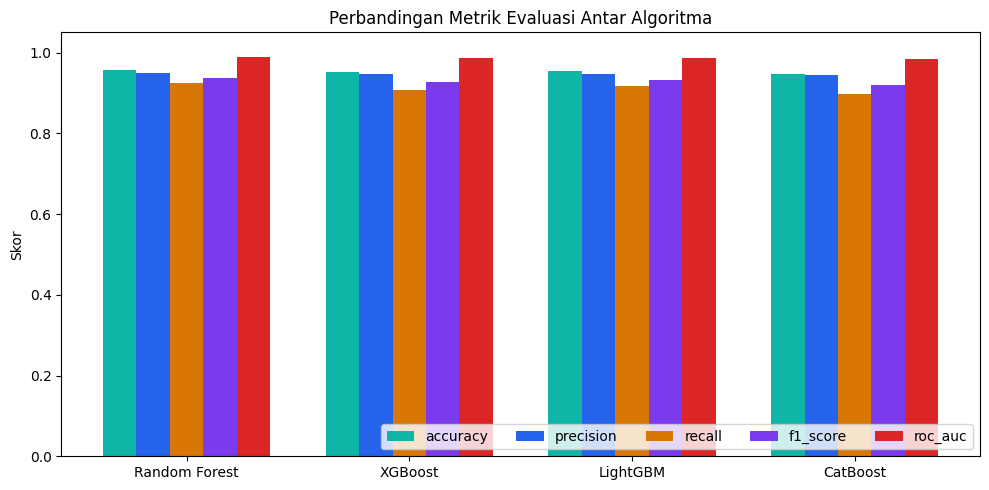

In [8]:
import numpy as np
from config import MODEL_NAMES

metric_cols = ['accuracy', 'precision', 'recall', 'f1_score', 'roc_auc']
plot_df = metrics_df.reset_index().rename(columns={'index': 'model'})
plot_df['model'] = plot_df['model'].map(lambda m: MODEL_NAMES.get(m, m))

x = np.arange(len(plot_df))
width = 0.15
fig, ax = plt.subplots(figsize=(10, 5))
colors_metric = ['#0FB5A6', '#2563EB', '#D97706', '#7C3AED', '#DC2626']
for i, col in enumerate(metric_cols):
    ax.bar(x + i * width, plot_df[col], width, label=col, color=colors_metric[i])
ax.set_xticks(x + width * (len(metric_cols) - 1) / 2)
ax.set_xticklabels(plot_df['model'])
ax.set_ylim(0, 1.05)
ax.set_ylabel('Skor')
ax.set_title('Perbandingan Metrik Evaluasi Antar Algoritma')
ax.legend(loc='lower right', ncol=len(metric_cols))
plt.tight_layout()
plt.show()

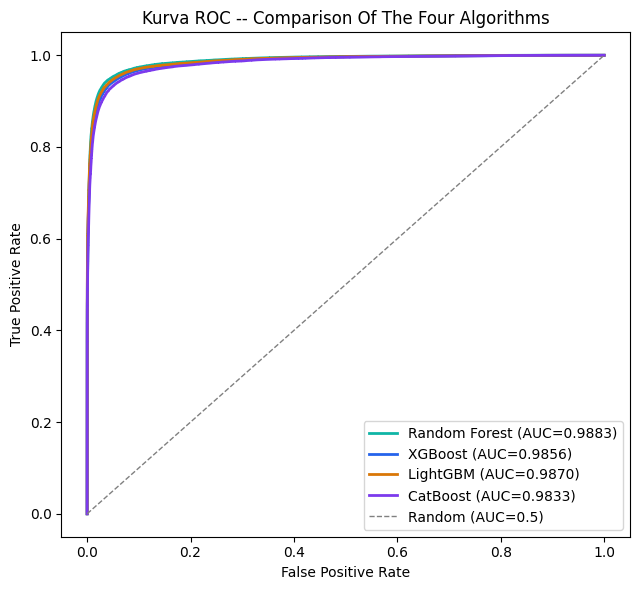

In [9]:
from sklearn.metrics import roc_curve
import joblib
from config import SCALER_PATH, model_path, MODEL_NAMES

scaler = joblib.load(SCALER_PATH)
Xte = scaler.transform(X_test.to_numpy())

fig, ax = plt.subplots(figsize=(6.5, 6))
colors_roc = ['#0FB5A6', '#2563EB', '#D97706', '#7C3AED']
for name, color in zip(MODEL_NAMES, colors_roc):
    mpath = model_path(name)
    if not mpath.exists():
        continue
    model = joblib.load(mpath)
    proba = model.predict_proba(Xte)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = results[name]['roc_auc']
    ax.plot(fpr, tpr, label=f"{MODEL_NAMES[name]} (AUC={auc:.4f})", color=color, linewidth=2)

ax.plot([0, 1], [0, 1], linestyle='--', color='gray', linewidth=1, label='Random (AUC=0.5)')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('Kurva ROC -- Comparison Of The Four Algorithms')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

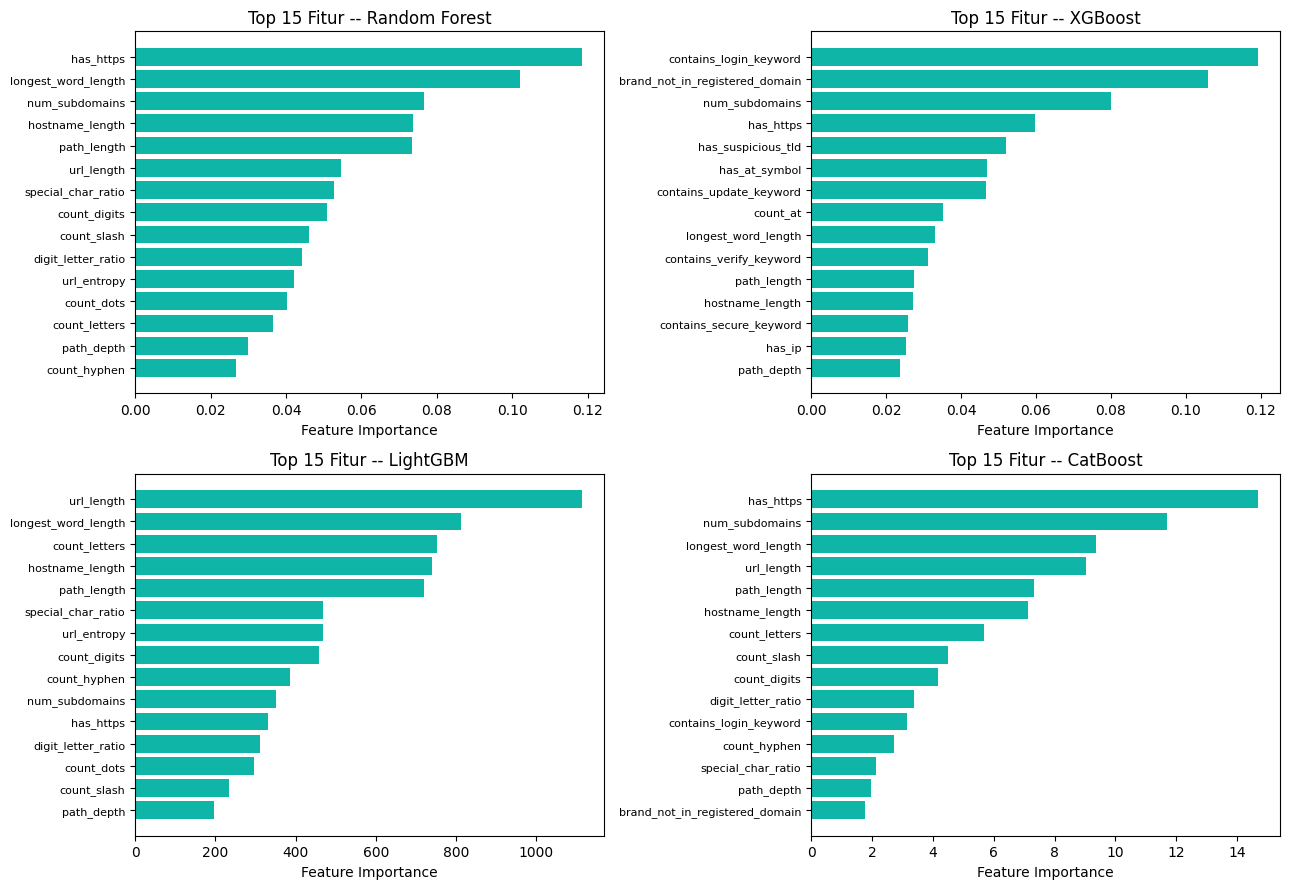

In [10]:
import numpy as np
import joblib
from config import model_path

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes = axes.flatten()
for ax, name in zip(axes, MODEL_NAMES):
    mpath = model_path(name)
    if not mpath.exists():
        ax.axis('off')
        continue
    model = joblib.load(mpath)
    importances = getattr(model, 'feature_importances_', None)
    if importances is None:
        ax.axis('off')
        continue
    order = np.argsort(importances)[::-1][:15]
    top_feats = [feature_names[i] for i in order]
    top_vals = importances[order]
    ax.barh(range(len(top_feats)), top_vals[::-1], color='#0FB5A6')
    ax.set_yticks(range(len(top_feats)))
    ax.set_yticklabels(list(reversed(top_feats)), fontsize=8)
    ax.set_title(f'Top 15 Fitur -- {MODEL_NAMES[name]}')
    ax.set_xlabel('Feature Importance')

plt.tight_layout()
plt.show()

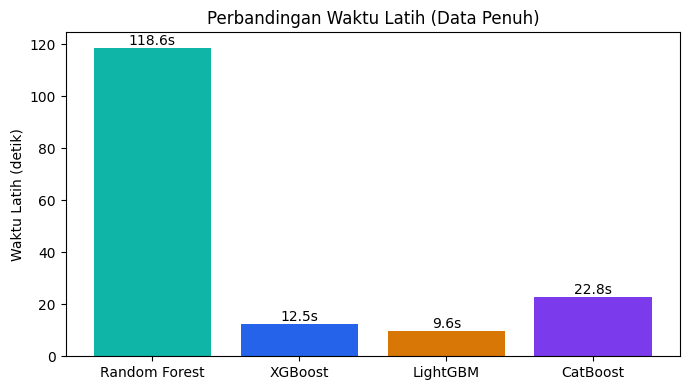

In [11]:
import numpy as np

fig, ax = plt.subplots(figsize=(7, 4))
names = [MODEL_NAMES.get(n, n) for n in training_times]
times = list(training_times.values())
bars = ax.bar(names, times, color=['#0FB5A6', '#2563EB', '#D97706', '#7C3AED'])
ax.set_ylabel('Waktu Latih (detik)')
ax.set_title('Perbandingan Waktu Latih (Data Penuh)')
for bar, t in zip(bars, times):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f'{t:.1f}s', ha='center', va='bottom')
plt.tight_layout()
plt.show()

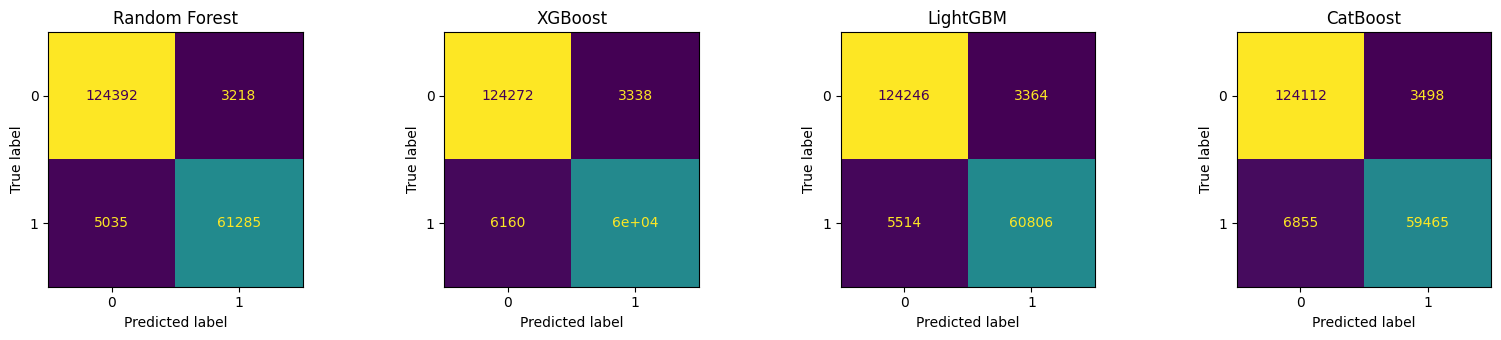

In [12]:
# Confusion matrix ringkas tiap model (opsional, butuh matplotlib).
import numpy as np, matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
import joblib
from config import SCALER_PATH, model_path, MODEL_NAMES

scaler = joblib.load(SCALER_PATH)
Xte = scaler.transform(X_test.to_numpy())
avail = [n for n in MODEL_NAMES if model_path(n).exists()]
fig, axes = plt.subplots(1, len(avail), figsize=(4*len(avail), 3.5))
if len(avail) == 1: axes = [axes]
for ax, name in zip(axes, avail):
    m = joblib.load(model_path(name))
    ConfusionMatrixDisplay.from_predictions(y_test, m.predict(Xte), ax=ax, colorbar=False)
    ax.set_title(MODEL_NAMES[name])
plt.tight_layout(); plt.show()

## 4. SHAP Explainer

Membuat TreeExplainer untuk tiap model agar aplikasi dapat menjelaskan prediksi.
Explainer disimpan ke `models_store/shap_explainer_*.pkl`.


In [13]:
from training.generate_shap import generate_all

generate_all()
print('SHAP explainer selesai dibuat.')

[shap] Membuat TreeExplainer untuk Random Forest ...
[shap] Explainer disimpan -> C:\xampp\htdocs\phishing-detector-xai\models_store\shap_explainer_random_forest.pkl
[shap] Membuat TreeExplainer untuk XGBoost ...
[shap] Explainer disimpan -> C:\xampp\htdocs\phishing-detector-xai\models_store\shap_explainer_xgboost.pkl
[shap] Membuat TreeExplainer untuk LightGBM ...
[shap] Explainer disimpan -> C:\xampp\htdocs\phishing-detector-xai\models_store\shap_explainer_lightgbm.pkl
[shap] Membuat TreeExplainer untuk CatBoost ...
[shap] Explainer disimpan -> C:\xampp\htdocs\phishing-detector-xai\models_store\shap_explainer_catboost.pkl
[shap] Semua explainer berhasil dibuat.
SHAP explainer selesai dibuat.


In [ ]:
import numpy as np
import joblib
import shap
from config import MODEL_NAMES, SCALER_PATH, explainer_path

best_name = max(results, key=lambda n: results[n]['f1_score'])
print('Model terbaik untuk visualisasi SHAP:', MODEL_NAMES[best_name])

explainer = joblib.load(explainer_path(best_name))
scaler = joblib.load(SCALER_PATH)

sample_idx = X_test.sample(n=min(2000, len(X_test)), random_state=42).index
X_sample = X_test.loc[sample_idx]
X_sample_scaled = scaler.transform(X_sample.to_numpy())

raw_shap = explainer.shap_values(X_sample_scaled)


def _normalize_shap_matrix(values, n_features):
    """Normalisasi berbagai bentuk output SHAP menjadi (n_samples, n_features)
    untuk kelas phishing -- lihat catatan bentuk di ml/predictor.py._shap_to_dict."""
    if isinstance(values, list):
        return np.asarray(values[-1])
    values = np.asarray(values)
    if values.ndim == 3:
        if values.shape[1] == n_features:
            return values[:, :, -1]
        if values.shape[-1] == n_features:
            return values[-1]
    return values


sv = _normalize_shap_matrix(raw_shap, len(feature_names))

shap.summary_plot(sv, X_sample, feature_names=feature_names, show=False, max_display=15)
plt.tight_layout()
plt.show()

Model terbaik untuk visualisasi SHAP: Random Forest


## Selesai

Artefak siap dipakai aplikasi web. Jalankan `python app.py` (atau `gunicorn wsgi:app`).
Jika memakai MySQL, jalankan `python scripts/init_db.py` lebih dulu.
